In [2]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

from sklearn.feature_selection import RFE
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error,r2_score
from sklearn.model_selection import train_test_split


from sklearn.preprocessing import StandardScaler



In [3]:
df_hour=pd.read_csv("hour.csv")

In [4]:
df_hour


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0000,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0000,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0000,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0000,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0000,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17374,17375,2012-12-31,1,1,12,19,0,1,1,2,0.26,0.2576,0.60,0.1642,11,108,119
17375,17376,2012-12-31,1,1,12,20,0,1,1,2,0.26,0.2576,0.60,0.1642,8,81,89
17376,17377,2012-12-31,1,1,12,21,0,1,1,1,0.26,0.2576,0.60,0.1642,7,83,90
17377,17378,2012-12-31,1,1,12,22,0,1,1,1,0.26,0.2727,0.56,0.1343,13,48,61


In [5]:
df_hour=df_hour.drop(columns=['casual','registered'])

In [6]:
#dropping dteday column as there are already in dataset
df_hour=df_hour.drop(columns=['dteday','instant'])

In [7]:
df_hour.isnull().mean()*100

season        0.0
yr            0.0
mnth          0.0
hr            0.0
holiday       0.0
weekday       0.0
workingday    0.0
weathersit    0.0
temp          0.0
atemp         0.0
hum           0.0
windspeed     0.0
cnt           0.0
dtype: float64

In [8]:
df_hour.duplicated().sum()

np.int64(2)

In [9]:

#print(df_hour[df_hour.duplicated(keep=False)])
print(df_hour[df_hour.duplicated()])

       season  yr  mnth  hr  holiday  weekday  workingday  weathersit  temp  \
8126        4   0    12   6        0        6           0           1  0.24   
13727       3   1     7   4        0        2           1           1  0.66   

        atemp   hum  windspeed  cnt  
8126   0.2576  0.65     0.1045   11  
13727  0.6061  0.83     0.0896    6  


In [10]:
df_hour=df_hour.drop_duplicates()


In [11]:
df_hour.duplicated().sum()

np.int64(0)

In [12]:
df_hour.dtypes

season          int64
yr              int64
mnth            int64
hr              int64
holiday         int64
weekday         int64
workingday      int64
weathersit      int64
temp          float64
atemp         float64
hum           float64
windspeed     float64
cnt             int64
dtype: object

In [13]:
#correlation
corr_hour=df_hour.corr(numeric_only=True)

In [14]:
corr_hour

,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,cnt
season,1.000000,-0.010691,0.830368,-0.006027,-0.009567,-0.002439,0.013842,-0.014456,0.312148,0.319498,0.150602,-0.149711,0.178179
yr,-0.010691,1.000000,-0.010390,-0.003851,0.006692,-0.004370,-0.002320,-0.019159,0.040793,0.039109,-0.083607,-0.008734,0.250525
mnth,0.830368,-0.010390,1.000000,-0.005691,0.018449,0.010269,-0.003349,0.005466,0.201836,0.208235,0.164410,-0.135330,0.120751
hr,-0.006027,-0.003851,-0.005691,1.000000,0.000460,-0.003461,0.002260,-0.020277,0.137612,0.133754,-0.276450,0.137180,0.394006
holiday,-0.009567,0.006692,0.018449,0.000460,1.000000,-0.102085,-0.252499,-0.017050,-0.027347,-0.030980,-0.010577,0.003973,-0.030949
weekday,-0.002439,-0.004370,0.010269,-0.003461,-0.102085,1.000000,0.036106,0.003349,-0.001656,-0.008691,-0.037142,0.011539,0.026959
workingday,0.013842,-0.002320,-0.003349,0.002260,-0.252499,0.036106,1.000000,0.044647,0.055253,0.054538,0.015658,-0.011858,0.030245
weathersit,-0.014456,-0.019159,0.005466,-0.020277,-0.017050,0.003349,0.044647,1.000000,-0.102669,-0.105592,0.418199,0.026169,-0.142514
temp,0.312148,0.040793,0.201836,0.137612,-0.027347,-0.001656,0.055253,-0.102669,1.000000,0.987671,-0.069931,-0.023141,0.404798
atemp,0.319498,0.039109,0.208235,0.133754,-0.030980,-0.008691,0.054538,-0.105592,0.987671,1.000000,-0.051960,-0.062357,0.400950


<Axes: >

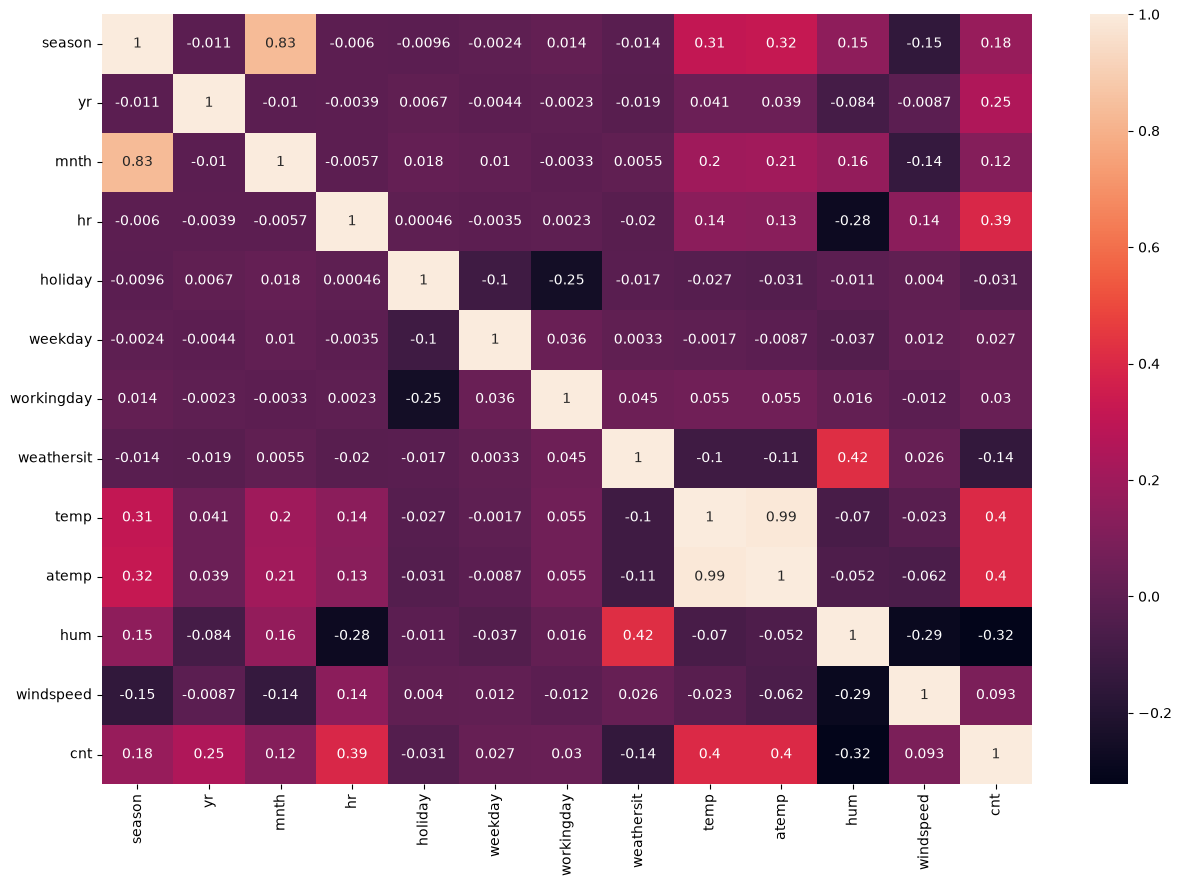

In [15]:
#heatmap
plt.figure(figsize=(15, 10))
sns.heatmap(corr_hour,annot=True)

In [16]:
corr_hour['cnt']

season        0.178179
yr            0.250525
mnth          0.120751
hr            0.394006
holiday      -0.030949
weekday       0.026959
workingday    0.030245
weathersit   -0.142514
temp          0.404798
atemp         0.400950
hum          -0.322872
windspeed     0.093155
cnt           1.000000
Name: cnt, dtype: float64

RFE METHOD

In [17]:


# 1. Features aur Target define karein
features = [
    
    'season',
    'yr',
    'mnth',
    'hr',
    'holiday',
    'weekday',
    'workingday',
    'weathersit',
    'temp',
    'atemp',
    'hum',
    'windspeed',
    
]

X = df_hour[features]
y = df_hour['cnt']

# Data ko Train aur Test sets mein split karein (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


## LINEAR REGRESSION + RFE

print('--- Training Linear Regression with RFE ---')
lr_model = LinearRegression()
rfe_lr = RFE(estimator=lr_model, n_features_to_select=8, step=1)
rfe_lr.fit(X_train, y_train)

# Linear Regression ke selected features
lr_selected = X.columns[rfe_lr.support_]
print(f'Linear Regression Selected Features: {list(lr_selected)}')

# Sirf unhi features par train aur test karein
X_train_lr = X_train[lr_selected]
X_test_lr = X_test[lr_selected]

lr_model.fit(X_train_lr, y_train)
lr_pred = lr_model.predict(X_test_lr)

lr_r2 = r2_score(y_test, lr_pred)
# RMSE ke liye MSE ka square root nikal rahe hain
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_pred))

print(f'Linear Regression R2 Score: {lr_r2:.4f}')
print(f'Linear Regression RMSE: {lr_rmse:.4f}\n')



# 3. RANDOM FOREST + RFE

print('--- Training Random Forest with RFE ---')
rf_model = RandomForestRegressor(random_state=42)
rfe_rf = RFE(estimator=rf_model, n_features_to_select=8, step=1)
rfe_rf.fit(X_train, y_train)

# Random Forest ke selected features
rf_selected = X.columns[rfe_rf.support_]
print(f'Random Forest Selected Features: {list(rf_selected)}')

# Sirf unhi features par train aur test karein
X_train_rf = X_train[rf_selected]
X_test_rf = X_test[rf_selected]

rf_model.fit(X_train_rf, y_train)
rf_pred = rf_model.predict(X_test_rf)

rf_r2 = r2_score(y_test, rf_pred)
# RMSE ke liye MSE ka square root nikal rahe hain
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))

print(f'Random Forest R2 Score: {rf_r2:.4f}')
print(f'Random Forest RMSE: {rf_rmse:.4f}')

--- Training Linear Regression with RFE ---
Linear Regression Selected Features: ['season', 'yr', 'hr', 'holiday', 'temp', 'atemp', 'hum', 'windspeed']
Linear Regression R2 Score: 0.3925
Linear Regression RMSE: 136.5675

--- Training Random Forest with RFE ---
Random Forest Selected Features: ['season', 'yr', 'mnth', 'hr', 'workingday', 'temp', 'atemp', 'hum']
Random Forest R2 Score: 0.9229
Random Forest RMSE: 48.6503


In [18]:
model = RandomForestRegressor()

features = [
   
    'season',
    'yr',
    'mnth',
    'hr',
    'holiday',
    'weekday',
    'workingday',
    'weathersit',
    'temp',
    'atemp',
    'hum',
    'windspeed',
    
]

X = df_hour[features]
y = df_hour['cnt']

# 3. RFE apply karein (top 5 features ke liye)
rfe = RFE(estimator=model, n_features_to_select=8, step=1)
rfe.fit(X, y)

# 4. Results check 
selected_features = X.columns[rfe.support_]
ranking = pd.DataFrame({'Feature': X.columns, 'Ranking': rfe.ranking_}).sort_values(
    by='Ranking'
)

print('Selected Top Features (Random Forest Regression):')
print(selected_features)
print('\nAll Features Ranking:')
print(ranking)

Selected Top Features (Random Forest Regression):
Index(['season', 'yr', 'hr', 'workingday', 'weathersit', 'temp', 'atemp',
       'hum'],
      dtype='str')

All Features Ranking:
       Feature  Ranking
0       season        1
1           yr        1
3           hr        1
7   weathersit        1
6   workingday        1
10         hum        1
9        atemp        1
8         temp        1
2         mnth        2
5      weekday        3
11   windspeed        4
4      holiday        5


C:\Users\syed_\AppData\Local\Temp\ipykernel_2580\3398932496.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


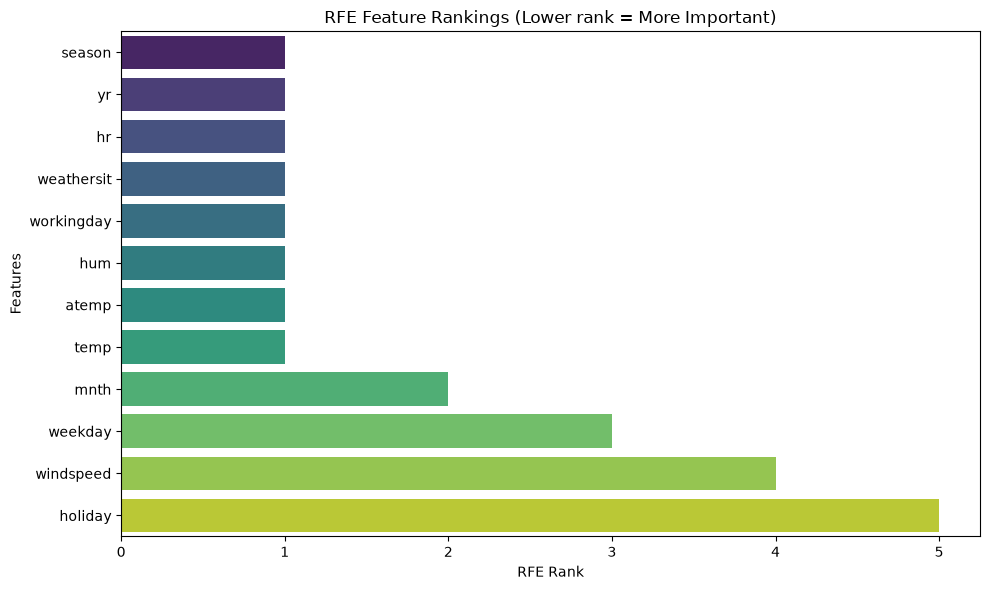

In [19]:
sorted_ranking = ranking.sort_values(by='Ranking', ascending=True)

plt.figure(figsize=(10, 6))
sns.barplot(
    x='Ranking', y='Feature', data=sorted_ranking, palette='viridis'
)
plt.title('RFE Feature Rankings (Lower rank = More Important)')
plt.xlabel('RFE Rank')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

In [20]:


features=[ 
    'season',
    'yr',
    'hr',
    'workingday',
    'weathersit',
    'temp',
    'atemp',
    'hum',
          ]


X=df_hour[features]
y=df_hour['cnt']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

print("size of training data:",X_train.shape,"        size of testing data:",X_test.shape)

size of training data: (13901, 8)         size of testing data: (3476, 8)


In [21]:


scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)    
X_test = scaler.transform(X_test)         

Applying ML Models

1) Linear Regression

In [22]:



model=LinearRegression()
model.fit(X_train,y_train)                  

train_pred=model.predict(X_train)                
print("For training data")
print("R2 for training data",  r2_score(y_train,train_pred))
print("MAE for training",  mean_absolute_error(y_train, train_pred))
print("RMSE for train data", np.sqrt(mean_squared_error(y_train,train_pred)))

print("For test data")
test_pred=model.predict(X_test)    
print("R2 on test data", r2_score(y_test,test_pred))
print("MAE for training",  mean_absolute_error(y_test, test_pred))
print("RMSE for test data", np.sqrt(mean_squared_error(y_test,test_pred)))


For training data
R2 for training data 0.3862406766304398
MAE for training 107.03792513215467
RMSE for train data 143.26810676906047
For test data
R2 on test data 0.391143072169589
MAE for training 103.04445815786856
RMSE for test data 136.71867372081056


I have tried ridge and lasso but it doesn't improve the results

In [43]:
from sklearn.linear_model import Ridge

# Model initialize aur train karein
ridge_model = Ridge(alpha=10.0, random_state=42)
ridge_model.fit(X_train, y_train)

# Training predictions aur metrics
ridge_train_pred = ridge_model.predict(X_train)
print("--- Ridge Regression Results ---")
print("R2 for training data:", r2_score(y_train, ridge_train_pred))
print("MAE for training:", mean_absolute_error(y_train, ridge_train_pred))
print("RMSE for train data:", np.sqrt(mean_squared_error(y_train, ridge_train_pred)))

# Test predictions aur metrics
ridge_test_pred = ridge_model.predict(X_test)
print("\nR2 on test data:", r2_score(y_test, ridge_test_pred))
print("MAE for test:", mean_absolute_error(y_test, ridge_test_pred))
print("RMSE for test data:", np.sqrt(mean_squared_error(y_test, ridge_test_pred)))

--- Ridge Regression Results ---
R2 for training data: 0.38624050677313837
MAE for training: 107.03447352561723
RMSE for train data: 143.26812659371436

R2 on test data: 0.39115496952143414
MAE for test: 103.04232442415812
RMSE for test data: 136.71733794056658


In [42]:
from sklearn.linear_model import Lasso

# Model initialize aur train karein
lasso_model = Lasso(alpha=1.0, random_state=42)
lasso_model.fit(X_train, y_train)

# Training predictions aur metrics
lasso_train_pred = lasso_model.predict(X_train)
print("--- Lasso Regression Results ---")
print("R2 for training data:", r2_score(y_train, lasso_train_pred))
print("MAE for training:", mean_absolute_error(y_train, lasso_train_pred))
print("RMSE for train data:", np.sqrt(mean_squared_error(y_train, lasso_train_pred)))

# Test predictions aur metrics
lasso_test_pred = lasso_model.predict(X_test)
print("\nR2 on test data:", r2_score(y_test, lasso_test_pred))
print("MAE for test:", mean_absolute_error(y_test, lasso_test_pred))
print("RMSE for test data:", np.sqrt(mean_squared_error(y_test, lasso_test_pred)))

--- Lasso Regression Results ---
R2 for training data: 0.3860807632940829
MAE for training: 106.82664609482424
RMSE for train data: 143.28676961290907

R2 on test data: 0.39132422203390016
MAE for test: 102.86294872089293
RMSE for test data: 136.69833362899203


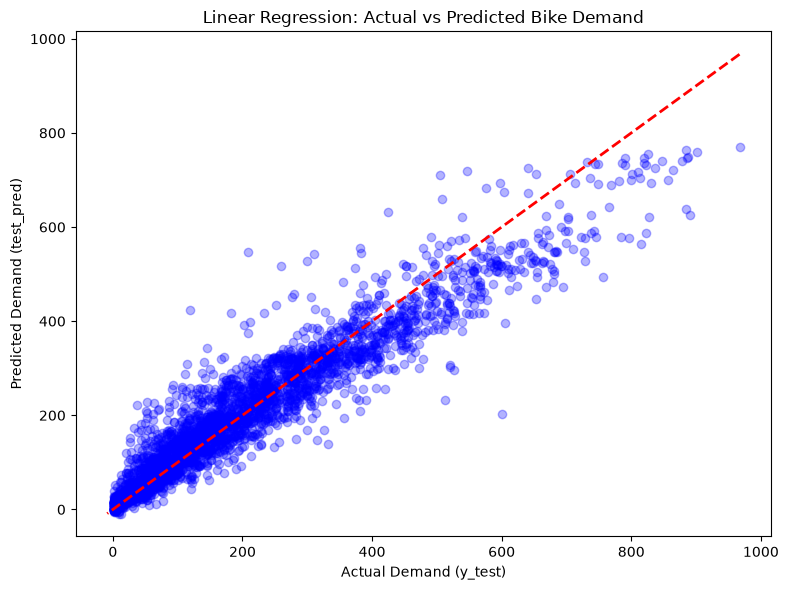

In [26]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, test_pred, alpha=0.3, color='blue')

# Draw a perfect prediction line (45-degree line)
p1 = max(max(test_pred), max(y_test))
p2 = min(min(test_pred), min(y_test))
plt.plot([p1, p2], [p1, p2], color='red', linestyle='--', lw=2)

plt.title('Linear Regression: Actual vs Predicted Bike Demand')
plt.xlabel('Actual Demand (y_test)')
plt.ylabel('Predicted Demand (test_pred)')
plt.tight_layout()
plt.show()

2) Random Forest Regressor

In [23]:

model=RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train,y_train)                   # train data se seekho

train_pred=model.predict(X_train)                #train data py hi predict kru
print("For training data")
print("R2 for training data",  r2_score(y_train,train_pred))
print("MAE for training",  mean_absolute_error(y_train, train_pred))
print("RMSE for train data", np.sqrt(mean_squared_error(y_train,train_pred)))

print("For test data")
test_pred=model.predict(X_test)    #test data py predict kru
print("R2 on test data", r2_score(y_test,test_pred))
print("MAE for training",  mean_absolute_error(y_test, test_pred))
print("RMSE for test data", np.sqrt(mean_squared_error(y_test,test_pred)))


For training data
R2 for training data 0.9872579177414714
MAE for training 12.213220773381716
RMSE for train data 20.642898297960734
For test data
R2 on test data 0.9251144665155107
MAE for training 30.19970786734682
RMSE for test data 47.94785405774809


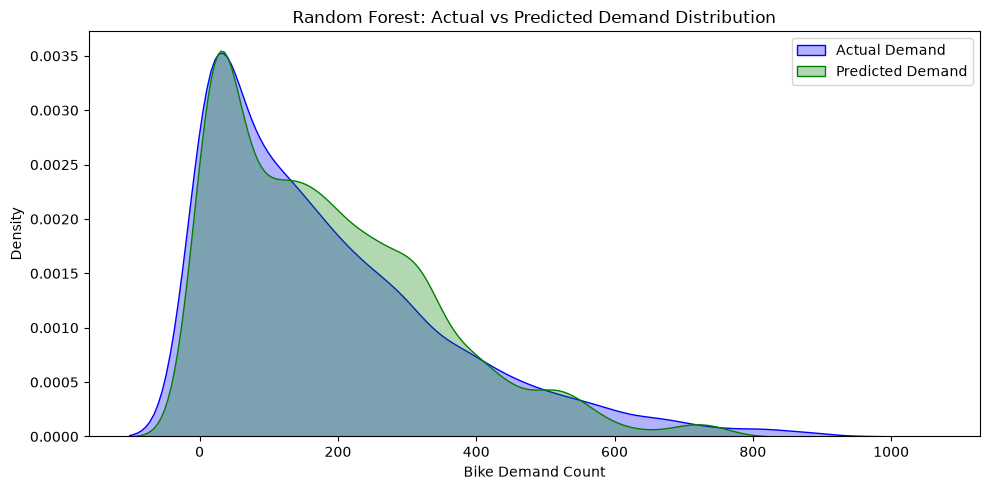

In [30]:
plt.figure(figsize=(10, 5))

# Actual demand distribution
sns.kdeplot(y_test, label='Actual Demand', color='blue', fill=True, alpha=0.3)

# Predicted demand distribution
sns.kdeplot(test_pred, label='Predicted Demand', color='green', fill=True, alpha=0.3)

plt.title('Random Forest: Actual vs Predicted Demand Distribution')
plt.xlabel('Bike Demand Count')
plt.ylabel('Density')
plt.legend()
plt.tight_layout()
plt.show()

3) KNN Regressor

In [24]:


model=KNeighborsRegressor(n_neighbors=5)
model.fit(X_train,y_train)                   # train data se seekho

train_pred=model.predict(X_train)                #train data py hi predict kru
print("For training data")
print("R2 for training data",  r2_score(y_train,train_pred))
print("MAE for training",  mean_absolute_error(y_train, train_pred))
print("RMSE for train data", np.sqrt(mean_squared_error(y_train,train_pred)))

print("For test data")
test_pred=model.predict(X_test)    #test data py predict kru
print("R2 on test data", r2_score(y_test,test_pred))
print("MAE for training",  mean_absolute_error(y_test, test_pred))
print("RMSE for test data", np.sqrt(mean_squared_error(y_test,test_pred)))


For training data
R2 for training data 0.8696829050063839
MAE for training 41.32469606503129
RMSE for train data 66.01629786150787
For test data
R2 on test data 0.7996704032225532
MAE for training 51.16858457997699
RMSE for test data 78.4228767320908


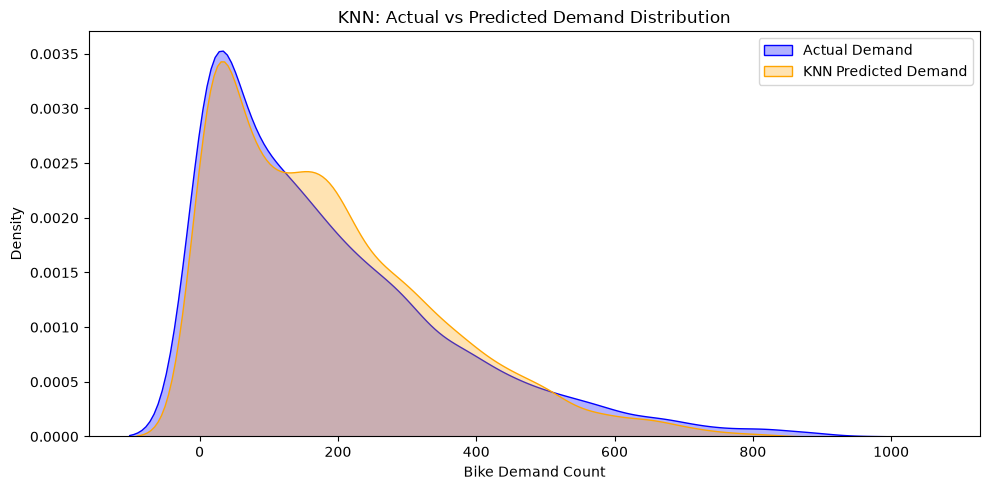

In [32]:
plt.figure(figsize=(10, 5))

# Actual demand distribution
sns.kdeplot(y_test, label='Actual Demand', color='blue', fill=True, alpha=0.3)

# KNN Predicted demand distribution
sns.kdeplot(test_pred, label='KNN Predicted Demand', color='orange', fill=True, alpha=0.3)

plt.title('KNN: Actual vs Predicted Demand Distribution')
plt.xlabel('Bike Demand Count')
plt.ylabel('Density')
plt.legend()
plt.tight_layout()
plt.show()

4) XGBoost Regressor

In [25]:
model=XGBRegressor(
    n_estimators=100, learning_rate=0.05, max_depth=5, random_state=42
)
model.fit(X_train,y_train)                   # train data se seekho

train_pred=model.predict(X_train)                #train data py hi predict kru
print("For training data")
print("R2 for training data",  r2_score(y_train,train_pred))
print("MAE for training",  mean_absolute_error(y_train, train_pred))
print("RMSE for train data", np.sqrt(mean_squared_error(y_train,train_pred)))

print("For test data")
test_pred=model.predict(X_test)    #test data py predict kru
print("R2 on test data", r2_score(y_test,test_pred))
print("MAE for training",  mean_absolute_error(y_test, test_pred))
print("RMSE for test data", np.sqrt(mean_squared_error(y_test,test_pred)))


For training data
R2 for training data 0.9101896286010742
MAE for training 36.01792526245117
RMSE for train data 54.804176873066666
For test data
R2 on test data 0.9073928594589233
MAE for training 35.87460708618164
RMSE for test data 53.32028445512083


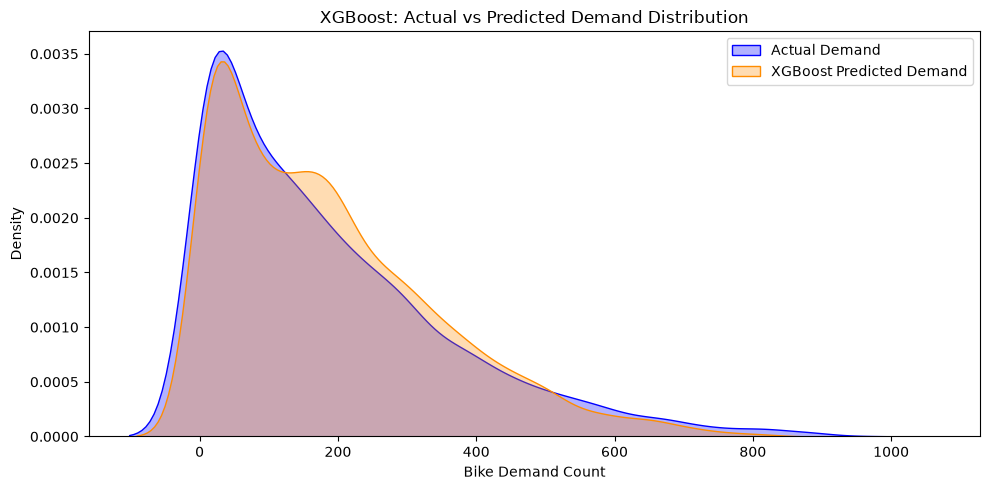

In [40]:
import seaborn as sns

plt.figure(figsize=(10, 5))

# Actual demand distribution
sns.kdeplot(y_test, label='Actual Demand', color='blue', fill=True, alpha=0.3)

# XGBoost Predicted demand distribution
sns.kdeplot(
    test_pred, label='XGBoost Predicted Demand', color='darkorange', fill=True, alpha=0.3
)

plt.title('XGBoost: Actual vs Predicted Demand Distribution')
plt.xlabel('Bike Demand Count')
plt.ylabel('Density')
plt.legend()
plt.tight_layout()
plt.show()